In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("../data/processed/clean_apartments.csv")

df.head()

,street_type,street_name,neighborhood,area_sqm,price_lei,year_built,transaction_period,price_per_sqm,transaction_quarter
0,Alee,BISTRICIOARA,colentina,91.41,469908.0,1989.0,2022-T1,5140.662947,1
1,Alee,BISTRICIOARA,colentina,56.44,252241.0,1987.0,2022-T1,4469.188519,1
2,Alee,BRASOVENI,tei,52.40,373347.0,1985.0,2022-T1,7124.942748,1
3,Alee,BURIDAVA,colentina,43.56,316527.0,2016.0,2022-T1,7266.460055,1
4,Alee,CIRCULUI,tei,59.60,495000.0,1960.0,2022-T1,8305.369128,1


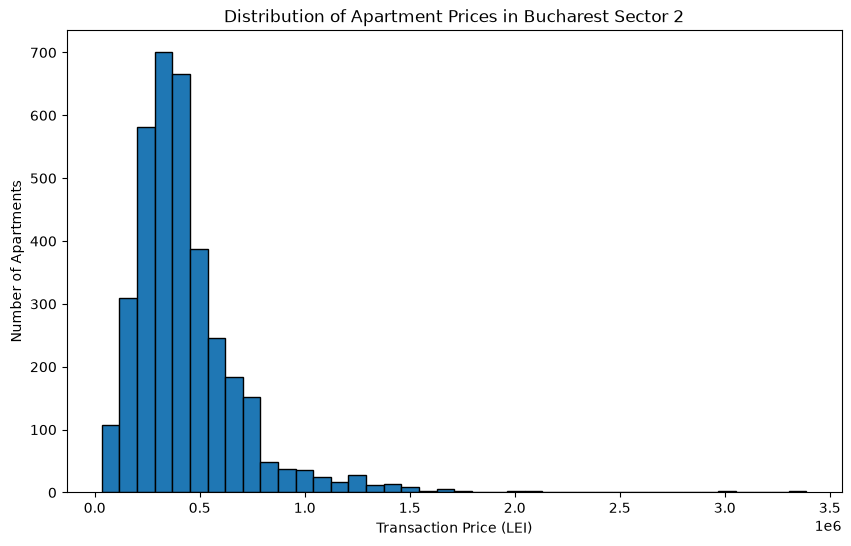

In [15]:
plt.figure(figsize=(10, 6))

plt.hist(df["price_lei"], bins=40, edgecolor="black")

plt.title("Distribution of Apartment Prices in Bucharest Sector 2")
plt.xlabel("Transaction Price (LEI)")
plt.ylabel("Number of Apartments")

plt.show()

In [16]:
print("Mean price:", round(df["price_lei"].mean(), 2))
print("Median price:", round(df["price_lei"].median(), 2))
print("Maximum price:", df["price_lei"].max())

Mean price: 435865.02
Median price: 380000.0
Maximum price: 3388797.0


In [17]:
neighborhood_prices = (
    df.groupby("neighborhood")["price_per_sqm"]
    .median()
    .sort_values(ascending=False)
)

neighborhood_prices

neighborhood
pipera sud         10067.316244
floreasca           9507.095132
centrala            8036.865119
vatra luminoasa     7244.294265
unknown             7208.188994
iancului            7027.051559
tei                 6930.312710
andronache          6715.130751
pantelimon          6540.373492
colentina           6273.995809
ion creanga         6167.098284
Name: price_per_sqm, dtype: float64

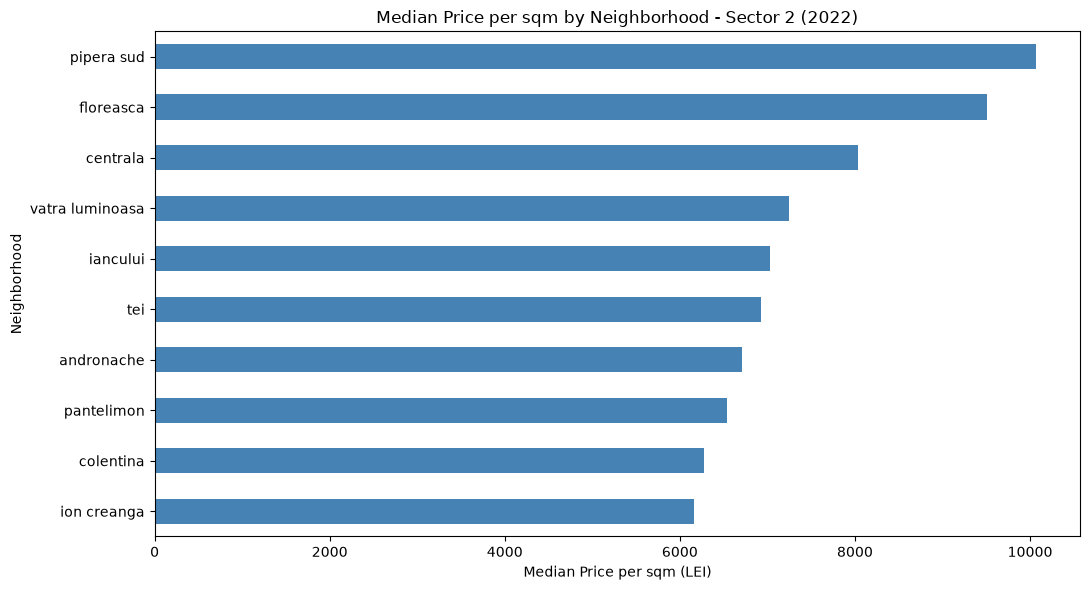

In [18]:
plt.figure(figsize=(11, 6))

neighborhood_prices.drop("unknown", errors="ignore").sort_values().plot(
    kind="barh",
    color="steelblue"
)

plt.title("Median Price per sqm by Neighborhood - Sector 2 (2022)")
plt.xlabel("Median Price per sqm (LEI)")
plt.ylabel("Neighborhood")

plt.tight_layout()
plt.show()

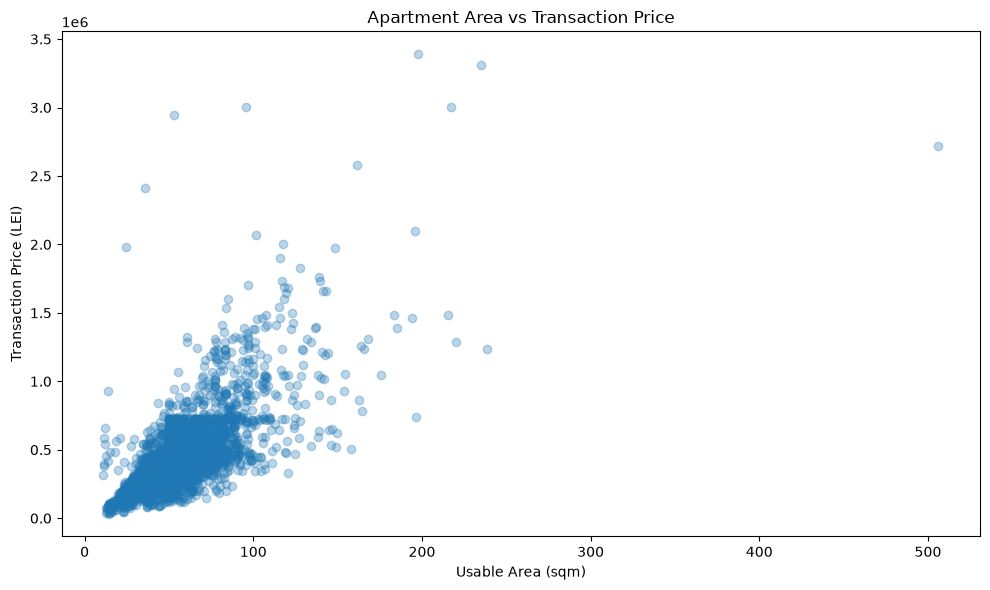

In [19]:
plt.figure(figsize=(10, 6))

plt.scatter(
    df["area_sqm"],
    df["price_lei"],
    alpha=0.3
)

plt.title("Apartment Area vs Transaction Price")
plt.xlabel("Usable Area (sqm)")
plt.ylabel("Transaction Price (LEI)")

plt.tight_layout()
plt.show()

In [20]:
correlation = df["area_sqm"].corr(df["price_lei"])

print("Correlation between area and price:", round(correlation, 3))

Correlation between area and price: 0.717


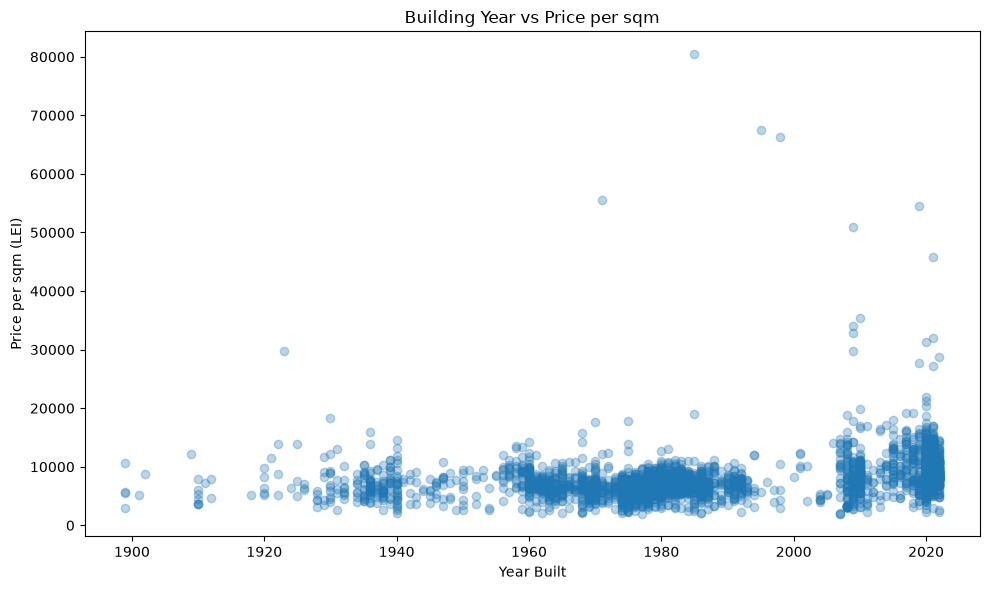

In [21]:
plt.figure(figsize=(10, 6))

plt.scatter(
    df["year_built"],
    df["price_per_sqm"],
    alpha=0.3
)

plt.title("Building Year vs Price per sqm")
plt.xlabel("Year Built")
plt.ylabel("Price per sqm (LEI)")

plt.tight_layout()
plt.show()

In [22]:
correlation = df["year_built"].corr(df["price_per_sqm"])

print("Correlation between building year and price per sqm:",
      round(correlation, 3))

Correlation between building year and price per sqm: 0.318


In [23]:
df["building_period"] = pd.cut(
    df["year_built"],
    bins=[1800, 1940, 1977, 1990, 2000, 2010, 2022],
    labels=[
        "Before 1940",
        "1941-1977",
        "1978-1990",
        "1991-2000",
        "2001-2010",
        "2011-2022"
    ]
)

df.groupby(
    "building_period",
    observed=True
)["price_per_sqm"].agg(["count", "median"])

,count,median
building_period,,
Before 1940,192,6347.459546
1941-1977,1091,6449.921047
1978-1990,961,7001.873429
1991-2000,89,6855.662242
2001-2010,229,8168.004269
2011-2022,1019,9355.379610


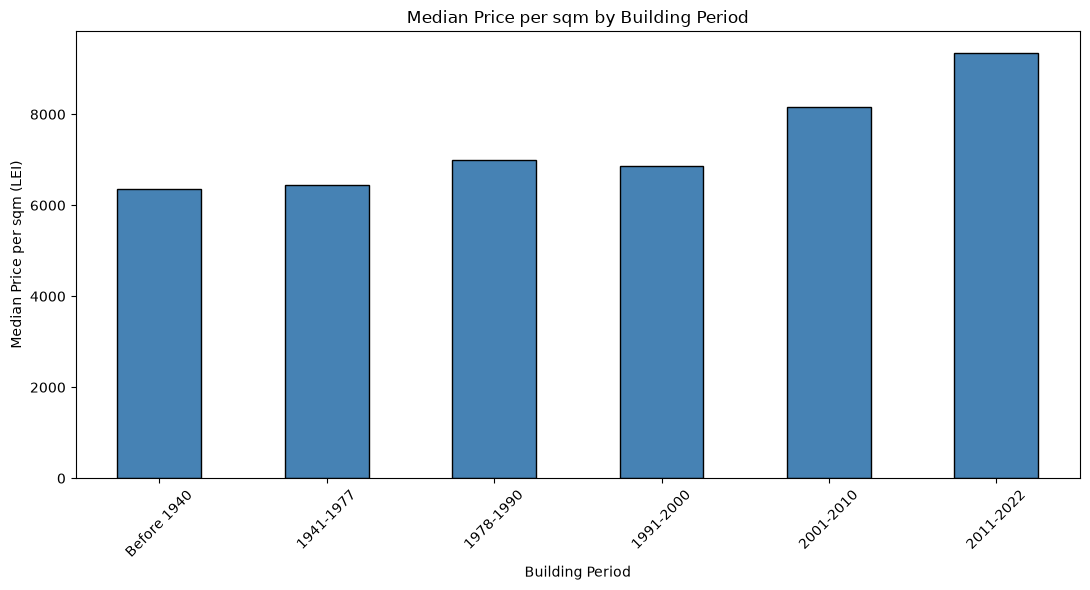

In [24]:
period_prices = (
    df.groupby("building_period", observed=True)["price_per_sqm"]
    .median()
)

plt.figure(figsize=(11, 6))

period_prices.plot(
    kind="bar",
    color="steelblue",
    edgecolor="black"
)

plt.title("Median Price per sqm by Building Period")
plt.xlabel("Building Period")
plt.ylabel("Median Price per sqm (LEI)")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [25]:
quarterly_prices = (
    df.groupby("transaction_quarter")["price_per_sqm"]
    .median()
    .sort_index()
)

quarterly_prices

transaction_quarter
1    7215.738009
2    7470.553670
3    7364.119318
4    6911.442006
Name: price_per_sqm, dtype: float64

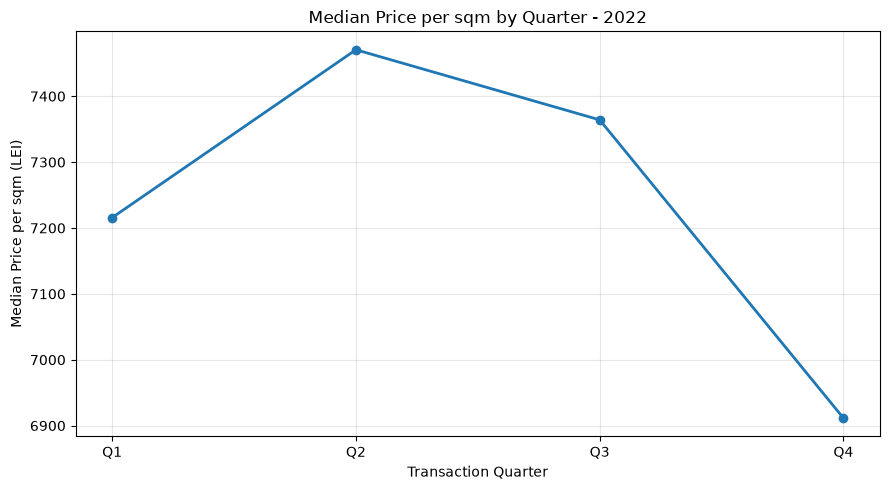

In [26]:
plt.figure(figsize=(9, 5))

plt.plot(
    quarterly_prices.index,
    quarterly_prices.values,
    marker="o",
    linewidth=2
)

plt.title("Median Price per sqm by Quarter - 2022")
plt.xlabel("Transaction Quarter")
plt.ylabel("Median Price per sqm (LEI)")

plt.xticks([1, 2, 3, 4], ["Q1", "Q2", "Q3", "Q4"])
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [27]:
numeric_columns = [
    "area_sqm",
    "price_lei",
    "year_built",
    "transaction_quarter"
]

correlation_matrix = df[numeric_columns].corr()

correlation_matrix.round(3)

,area_sqm,price_lei,year_built,transaction_quarter
area_sqm,1.000,0.717,0.129,-0.011
price_lei,0.717,1.000,0.324,-0.018
year_built,0.129,0.324,1.000,-0.053
transaction_quarter,-0.011,-0.018,-0.053,1.000
